# MAGPI Resolved Emission Line Map Products Viewer & Property Maps

This notebook is intended to act as a starting point for working with the MAGPI 'Resolved Emission Line Map Products' located in `MAGPI_ELDR_Map_products.zip`. For details on the FITS files, please refer to `README_MAGPI_ELDR_Map_products.txt` which is inside the zip directory and Battisti et al. (2026). 

For a given **MAGPIID** this notebook will:
1. Plot every extension in the FITS file (fluxes, kinematics, D4000, masks, etc.)
2. Compute and plot a few derived products:
   - Line S/N maps
   - E(B-V)$_{gas}$ (based on Balmer-decrement) for a custom S/N threshold on H$\alpha$ and H$\beta$
   - Dust-corrected H$\alpha$ luminosity and SFR(H$\alpha$)
   - BPT diagnostic diagrams ([NII]/H$\alpha$ and [SII]/H$\alpha$) and a spatial BPT classification map
   - Gas-phase metallicity via the N2S2 calibration
   - Quality-cut D4000 and gas velocity maps

Every plotting function has a `save=True/False` option (and a shared `SAVE_FIGS` global default) to write figures to `output_dir`.

**Default example galaxy:** `MAGPI1202197197`

> **Note on assumptions:** The nebular dust attenuation curve assumed is the the average MW extinction curve from Fitzpatrick (2019) with $R_V=3.1$. The SFR(H$\alpha$) calibration is Calzetti et al. (2013). The cosmology used for luminosity distances is FlatLambdaCDM. BPT diagnostics are based on Kewley et al. (2001,2006) and Kauffmann et al. (2003). The N2S2 calibration is based on Dopita et al. (2016). Adjust the the cells below if you prefer to use different values or calibrations.


In [1]:
# ================== Imports ==================
import os
import glob
import warnings

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from astropy.io import fits
#from astropy.cosmology import Planck18 as cosmo
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)  # pick your preferred cosmology

warnings.filterwarnings("ignore", category=RuntimeWarning)  # NaN comparisons etc.
plt.rcParams["image.origin"] = "lower"
plt.rcParams["figure.dpi"] = 100


## Configuration

Edit these and re-run the notebook (or just re-run cells below) for a different object.

In [4]:
# ================== User configuration ==================
MAGPIID = "1202197197"          # MAGPI ID (string, no "MAGPI" prefix)

# Directory containing the *_Map_products.fits file(s). Defaults to the 
# notebook's own directory -- change this to wherever your MAGPI FITS files
# live (e.g. a shared data drive).
#DATA_DIR = "."
DATA_DIR = "/Users/00115191/Research_data/MAGPI/GIST_results_v2.2.1/MAGPI_ELDR_Map_products"
OUTPUT_DIR = "./MAGPI_plots"    # where figures get saved

SAVE_FIGS = False                # default save behaviour for every plotting function
#SAVE_FIGS = True                # default save behaviour for every plotting function
FIG_FORMAT = "png"               # 'png', 'pdf', etc.
FIG_DPI = 150

os.makedirs(OUTPUT_DIR, exist_ok=True)


## Locate and load the FITS file

In [7]:
def find_map_file(magpiid, data_dir=DATA_DIR):
    '''Find the Map_products FITS file for a given MAGPIID in data_dir.'''
    candidates = sorted(glob.glob(os.path.join(data_dir, f"*{magpiid}*Map_products*.fits")))
    if not candidates:
        # fall back: any fits file containing the ID
        candidates = sorted(glob.glob(os.path.join(data_dir, f"*{magpiid}*.fits")))
    if not candidates:
        raise FileNotFoundError(
            f"No FITS file found for MAGPIID={magpiid} in {data_dir}"
        )
    if len(candidates) > 1:
        print(f"[find_map_file] Multiple matches found, using the first:\n  " +
              "\n  ".join(candidates))
    return candidates[0]


class MagpiMaps:
    '''Container for a MAGPI GIST/GandALF emission-line map FITS file.'''

    def __init__(self, magpiid, data_dir=DATA_DIR):
        self.magpiid = str(magpiid)
        self.filepath = find_map_file(self.magpiid, data_dir)

        with fits.open(self.filepath) as hdul:
            self.primary_header = hdul[0].header.copy()
            self.ext_names = [h.name for h in hdul if h.name != "PRIMARY"]
            self.data = {h.name: h.data.copy() for h in hdul if h.name != "PRIMARY"}
            self.ny, self.nx = self.data["Ha_F"].shape

        hdr = self.primary_header
        self.z_spec = float(hdr.get("ZMARZ", np.nan))
        self.zflag = hdr.get("ZFLGMARZ", None)
        self.ebv_mw = float(hdr.get("EBV_MW", 0.0))
        self.vtieline = hdr.get("VTIELINE", None)
        self.x_origin = hdr.get("X_ORIGIN", None)
        self.y_origin = hdr.get("Y_ORIGIN", None)
        self.object_name = hdr.get("OBJECT", None)

        self.dilated_mask = self.data["DILATED_MASK"]      # 0=inside, 1=outside
        self.undilated_mask = self.data["UNDILATED_MASK"]  # 0=inside, 1=outside

    def __getitem__(self, key):
        return self.data[key]

    def get(self, key):
        return self.data.get(key)

    def summary(self):
        print(f"MAGPI{self.magpiid}  ({self.object_name})")
        print(f"  file        : {self.filepath}")
        print(f"  shape (y,x) : {self.data['Ha_F'].shape}")
        print(f"  z_spec      : {self.z_spec:.5f}  (ZFLGMARZ={self.zflag})")
        print(f"  E(B-V)_MW   : {self.ebv_mw}")
        print(f"  V-tie line  : {self.vtieline}")
        print(f"  extensions  : {len(self.ext_names)}")


gal = MagpiMaps(MAGPIID, DATA_DIR)
gal.summary()


MAGPI1202197197  (GAMAJ114121.30-013456.2)
  file        : /Users/00115191/Research_data/MAGPI/GIST_results_v2.2.1/MAGPI_ELDR_Map_products/MAGPI1202197197_Map_products.fits
  shape (y,x) : (82, 84)
  z_spec      : 0.29130  (ZFLGMARZ=4.0)
  E(B-V)_MW   : 0.0134
  V-tie line  : Ha
  extensions  : 36


## Extension reference

The extension list, straight from the file's primary header / the README,
for quick lookup.

In [10]:
EXT_DESCRIPTIONS = {
    "COLLAPSED_SPECTRUM": "White-light image (summed spectrum)",
    "UNDILATED_MASK": "ProFound segmentation mask (undilated); 0=inside,1=outside",
    "DILATED_MASK": "ProFound segmentation mask (dilated); 0=inside,1=outside",
    "REDUCED_CHI2": "Reduced chi^2 of GIST fit",
    "D4000_OBS": "D4000 from observed spectrum",
    "D4000_OBS_ERR": "D4000 error, observed spectrum",
    "D4000_FIT": "D4000 from GIST continuum fit",
    "Dn4000_OBS": "Narrow D4000 from observed spectrum",
    "Dn4000_OBS_ERR": "Narrow D4000 error, observed spectrum",
    "Dn4000_FIT": "Narrow D4000 from continuum fit",
    "EBV_GAS": "[mag] E(B-V) from Balmer decrement (as provided)",
    "EBVERR_GAS": "[mag] error on above",
    "V_GAS": "[km/s] gas velocity (tied lines, see VTIELINE)",
    "VERR_GAS": "[km/s] error on gas velocity",
    "SIGMA_GAS": "[km/s] gas velocity dispersion",
    "SIGMAERR_GAS": "[km/s] error on gas velocity dispersion",
    "OII_TOT_F": "[OII]3727+3730 total flux",
    "OII_TOT_FERR": "error",
    "Hd_F": "H-delta flux",
    "Hd_FERR": "error",
    "Hg_F": "H-gamma flux",
    "Hg_FERR": "error",
    "Hb_F": "H-beta flux",
    "Hb_FERR": "error",
    "OIII_5008_F": "[OIII]5007 flux",
    "OIII_5008_FERR": "error",
    "OI_6302_F": "[OI]6300 flux",
    "OI_6302_FERR": "error",
    "Ha_F": "H-alpha flux",
    "Ha_FERR": "error",
    "NII_6585_F": "[NII]6583 flux",
    "NII_6585_FERR": "error",
    "SII_6718_F": "[SII]6717 flux",
    "SII_6718_FERR": "error",
    "SII_6733_F": "[SII]6731 flux",
    "SII_6733_FERR": "error",
}
# Flux units for all *_F / *_FERR extensions: 1e-20 erg/s/cm^2 per spaxel

for name in gal.ext_names:
    print(f"{name:18s} {EXT_DESCRIPTIONS.get(name, '')}")


COLLAPSED_SPECTRUM White-light image (summed spectrum)
UNDILATED_MASK     ProFound segmentation mask (undilated); 0=inside,1=outside
DILATED_MASK       ProFound segmentation mask (dilated); 0=inside,1=outside
REDUCED_CHI2       Reduced chi^2 of GIST fit
D4000_OBS          D4000 from observed spectrum
D4000_OBS_ERR      D4000 error, observed spectrum
D4000_FIT          D4000 from GIST continuum fit
Dn4000_OBS         Narrow D4000 from observed spectrum
Dn4000_OBS_ERR     Narrow D4000 error, observed spectrum
Dn4000_FIT         Narrow D4000 from continuum fit
EBV_GAS            [mag] E(B-V) from Balmer decrement (as provided)
EBVERR_GAS         [mag] error on above
V_GAS              [km/s] gas velocity (tied lines, see VTIELINE)
VERR_GAS           [km/s] error on gas velocity
SIGMA_GAS          [km/s] gas velocity dispersion
SIGMAERR_GAS       [km/s] error on gas velocity dispersion
OII_TOT_F          [OII]3727+3730 total flux
OII_TOT_FERR       error
Hd_F               H-delta flux
Hd_

## Generic plotting helper

In [13]:
def _savefig(fig, save, filename):
    do_save = SAVE_FIGS if save is None else save
    if do_save:
        path = os.path.join(OUTPUT_DIR, filename)
        fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
        print(f"[saved] {path}")


def plot_map(gal, data, title, cmap="viridis", vmin=None, vmax=None,
             mask_dilated=False, symmetric=False, cbar_label=None,
             ax=None, save=None, filename=None, percentile=(1, 99)):
    '''Plot a single 2D map with sensible default scaling.
    mask_dilated : mask out spaxels where gal.dilated_mask == 1
    symmetric: force a symmetric colour scale around 0 (e.g. velocity maps)
    percentile: used to set vmin/vmax automatically if not given
    '''
    d = np.array(data, dtype=float)
    if mask_dilated:
        d = np.where(gal.dilated_mask == 1, np.nan, d)

    if vmin is None or vmax is None:
        finite = d[np.isfinite(d)]
        if finite.size == 0:
            auto_vmin, auto_vmax = 0, 1
        else:
            auto_vmin, auto_vmax = np.nanpercentile(finite, percentile)
        if vmin is None:
            vmin = auto_vmin
        if vmax is None:
            vmax = auto_vmax

    if symmetric:
        m = max(abs(vmin), abs(vmax))
        vmin, vmax = -m, m
        if cmap == "viridis":
            cmap = "RdBu_r"

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(5.5, 5))
    else:
        fig = ax.figure

    im = ax.imshow(d, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x [spaxel]")
    ax.set_ylabel("y [spaxel]")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    if cbar_label:
        cb.set_label(cbar_label, fontsize=9)

    if standalone:
        fig.tight_layout()
        if filename is None:
            filename = f"MAGPI{gal.magpiid}_{title.replace(' ', '_').replace('/', '-')}.{FIG_FORMAT}"
        _savefig(fig, save, filename)
        plt.show()
    return im


## 1. Plot extension maps

### 1a. All extensions at once

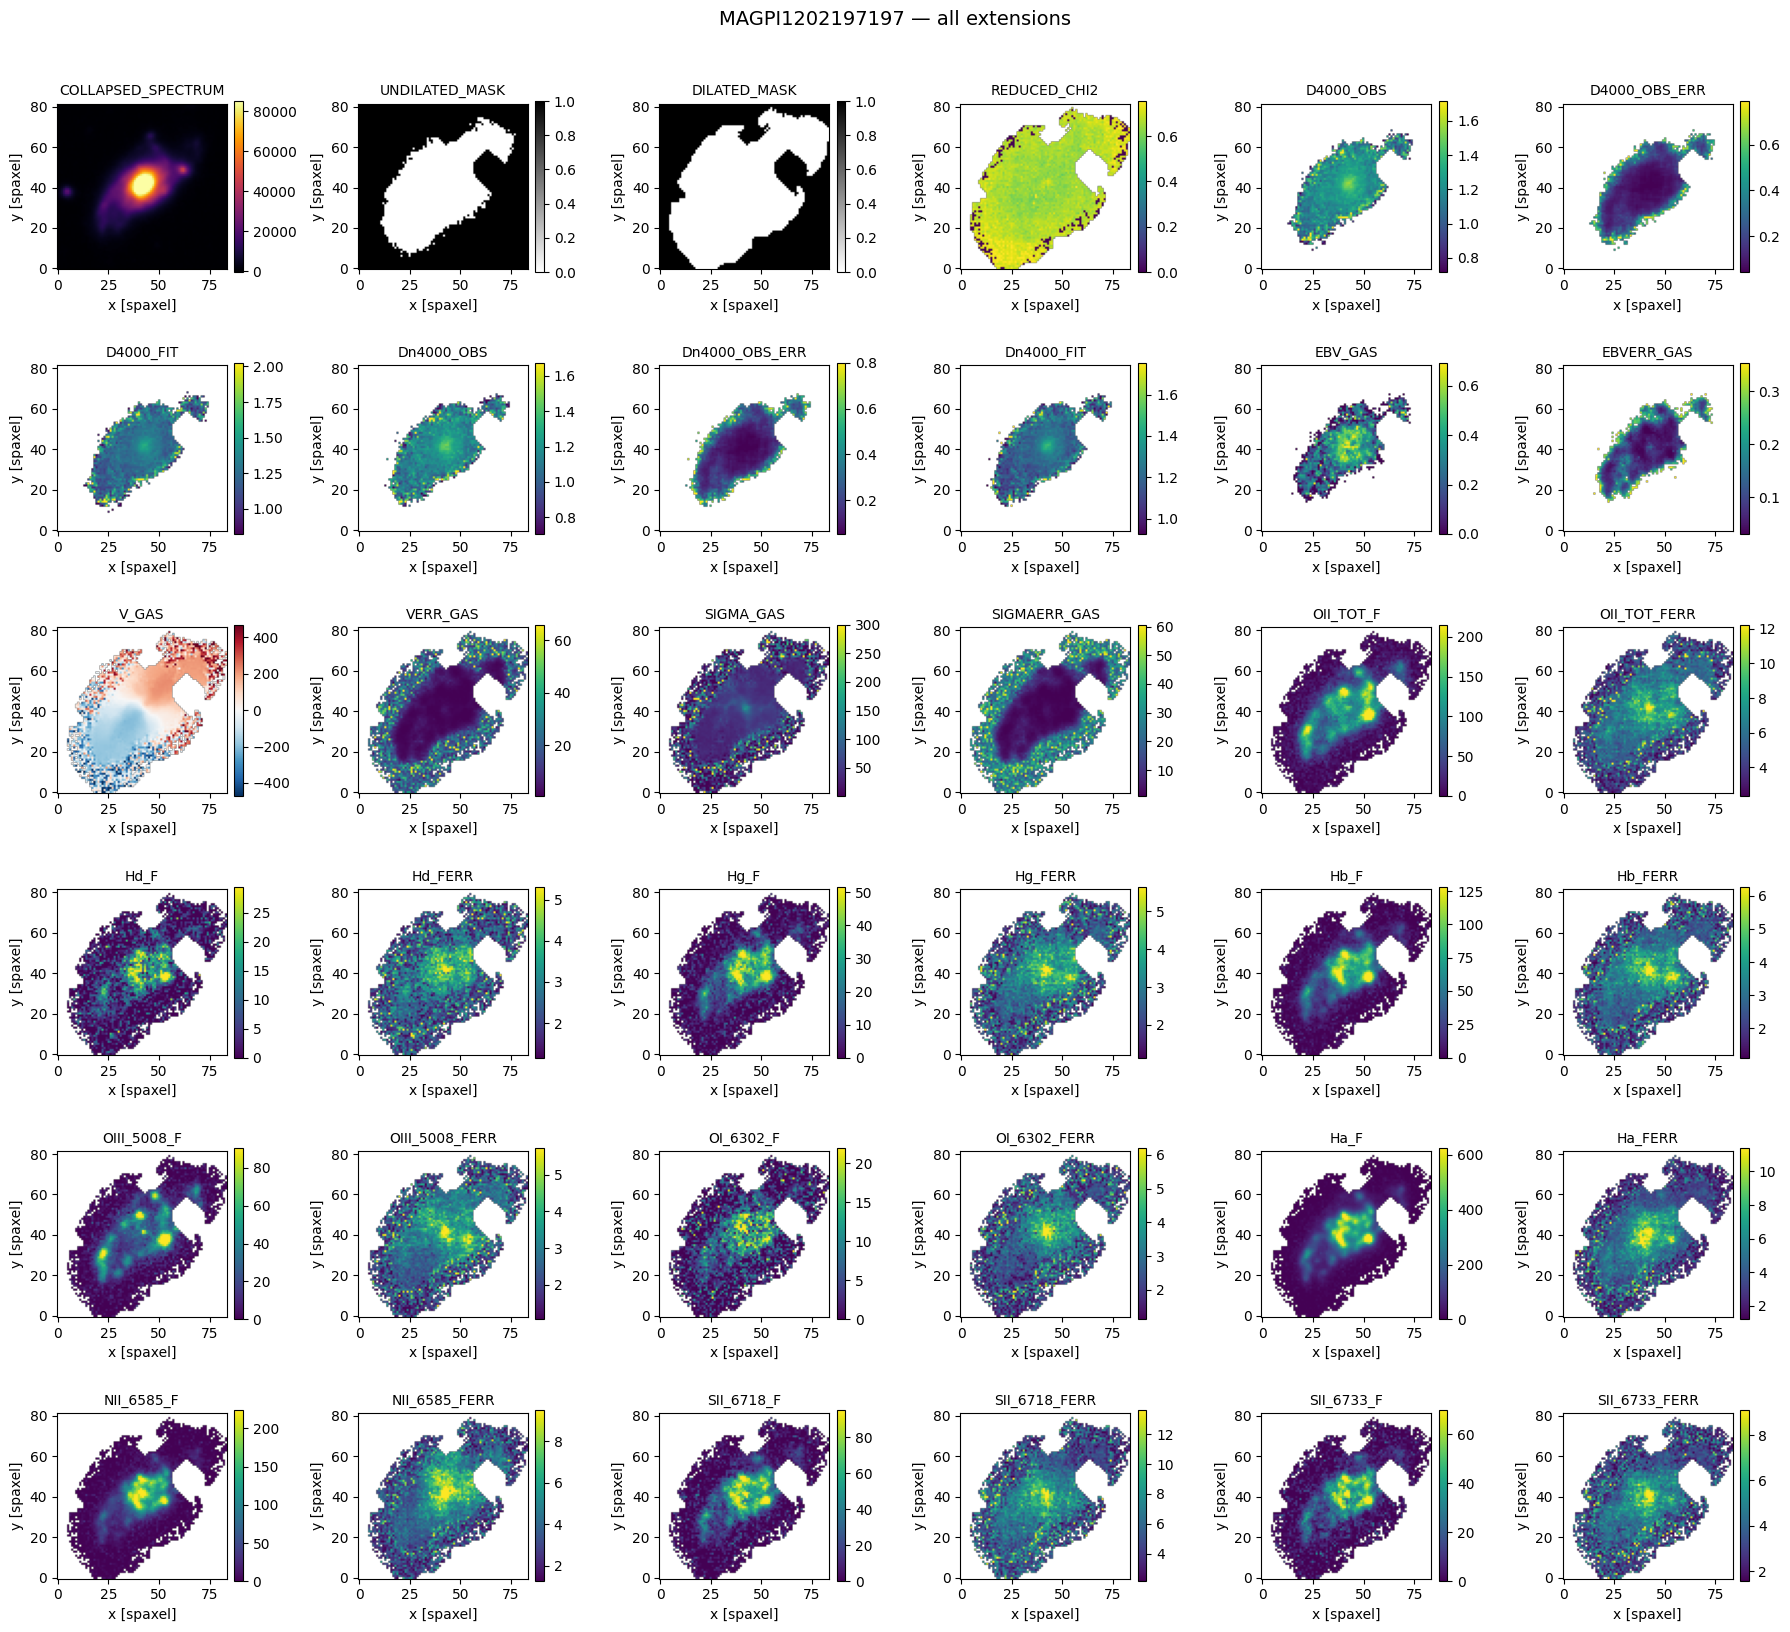

In [16]:
def plot_all_extensions(gal, save=None, filename=None):
    names = gal.ext_names
    ncols = 6
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.7 * nrows))
    axes = np.atleast_2d(axes)

    for i, name in enumerate(names):
        ax = axes[i // ncols, i % ncols]
        d = gal.data[name]

        if name in ("DILATED_MASK", "UNDILATED_MASK"):
            plot_map(gal, d, name, cmap="gray_r", vmin=0, vmax=1, ax=ax)
        elif name in ("V_GAS",):
            plot_map(gal, d, name, mask_dilated=True, symmetric=True, ax=ax) #change mask_dilated=False to show all spaxels
        elif name == "COLLAPSED_SPECTRUM":
            plot_map(gal, d, name, cmap="inferno", ax=ax)
        else:
            plot_map(gal, d, name, mask_dilated=True, ax=ax) #change mask_dilated=False to show all spaxels

    # blank any unused panels
    for j in range(len(names), nrows * ncols):
        axes[j // ncols, j % ncols].axis("off")

    fig.suptitle(f"MAGPI{gal.magpiid} — all extensions", y=1.01, fontsize=14)
    fig.tight_layout()
    if filename is None:
        filename = f"MAGPI{gal.magpiid}_all_extensions.{FIG_FORMAT}"
    _savefig(fig, save, filename)
    plt.show()


plot_all_extensions(gal)


### 1b. Individual extension plots

Use `plot_map` directly for any single extension, e.g.:

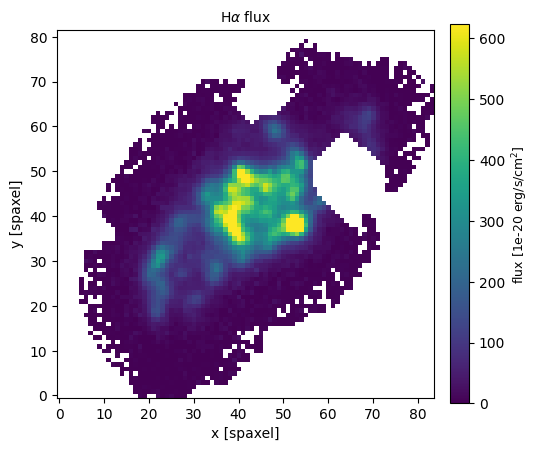

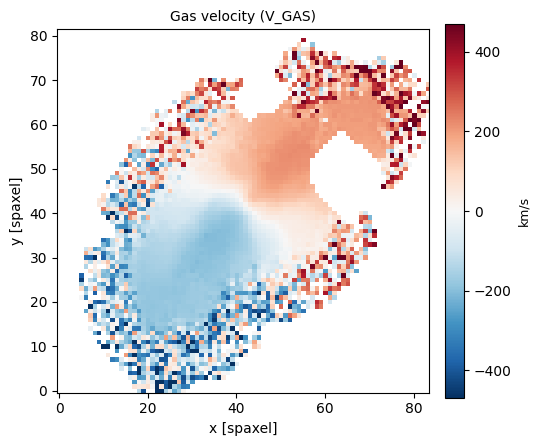

In [18]:
plot_map(gal, gal["Ha_F"], r"H$\alpha$ flux", cbar_label="flux [1e-20 erg/s/cm$^2$]", mask_dilated=True,
         save=False)

plot_map(gal, gal["V_GAS"], "Gas velocity (V_GAS)", mask_dilated=True, symmetric=True,
         cbar_label="km/s", save=False)


## 2. Derived quantities: setup

Line-flux units are $10^{-20}\,\mathrm{erg\,s^{-1}\,cm^{-2}}$ per spaxel.


In [320]:
# Replace values below with your preferred values, as desired.
# --- Nebular dust attenuation curve coefficients (Fitzpatrick 2019, Rv=3.1) ---
k_Hb = 3.688
k_Ha = 2.528

CASE_B_RATIO = 2.863     # intrinsic Ha/Hb for case-B recombination, n=100cm^-3, Te=1e4 K
SFR_CALIB = 5.5e-42      # SFR = SFR_CALIB * L(Ha) [erg/s], Calzetti et al. 2013

SN_LINE_CUT = 3          # generic line S/N cut (BPT, SFR mask, etc.)
SN_BALMER_CUT = 2        # S/N cut used for Balmer-decrement / dust correction
D4000_SN_CUT = 4         # S/N cut for D4000 map
D4000_MAX = 10           # sanity cap on D4000
VEL_ERR_CUT = 10         # [km/s] max VERR_GAS for a "good" velocity spaxel


def snr(flux, err):
    with np.errstate(divide="ignore", invalid="ignore"):
        return flux / err


def safe_log10(x):
    with np.errstate(divide="ignore", invalid="ignore"):
        out = np.log10(x)
    out[~np.isfinite(out)] = np.nan
    return out


# --- pull out the line fluxes/errors we need ---
OII_F, OII_FERR = gal["OII_TOT_F"], gal["OII_TOT_FERR"]
Hb_F, Hb_FERR = gal["Hb_F"], gal["Hb_FERR"]
OIII_F, OIII_FERR = gal["OIII_5008_F"], gal["OIII_5008_FERR"]
OI_F, OI_FERR = gal["OI_6302_F"], gal["OI_6302_FERR"]
Ha_F, Ha_FERR = gal["Ha_F"], gal["Ha_FERR"]
NII_F, NII_FERR = gal["NII_6585_F"], gal["NII_6585_FERR"]
SII1_F, SII1_FERR = gal["SII_6718_F"], gal["SII_6718_FERR"]
SII2_F, SII2_FERR = gal["SII_6733_F"], gal["SII_6733_FERR"]

SII_tot_F = SII1_F + SII2_F
SII_tot_FERR = np.sqrt(SII1_FERR**2 + SII2_FERR**2)

OII_SNR = snr(OII_F, OII_FERR)
Hb_SNR = snr(Hb_F, Hb_FERR)
OIII_SNR = snr(OIII_F, OIII_FERR)
OI_SNR = snr(OI_F, OI_FERR)
Ha_SNR = snr(Ha_F, Ha_FERR)
NII_SNR = snr(NII_F, NII_FERR)
SII_SNR = snr(SII_tot_F, SII_tot_FERR)

print("Line S/N maps computed for: OII(tot), Hb, OIII5008, OI6302, Ha, NII6585, SII(tot)")


Line S/N maps computed for: OII(tot), Hb, OIII5008, OI6302, Ha, NII6585, SII(tot)


### 2a. Line S/N maps

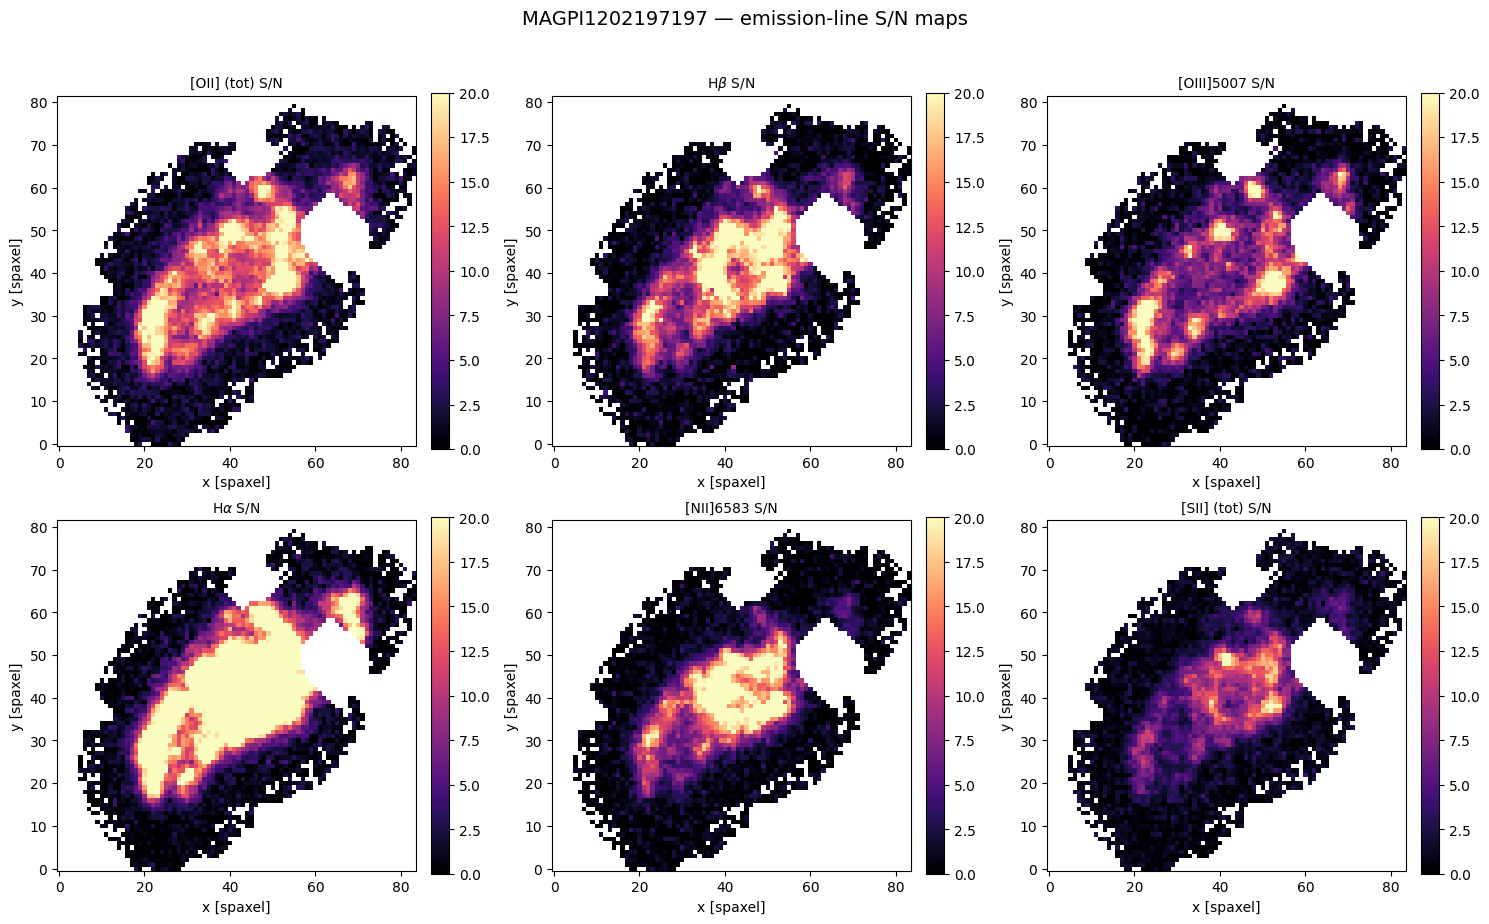

In [322]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
snr_maps = [
    (OII_SNR, r"[OII] (tot) S/N"),
    (Hb_SNR, r"H$\beta$ S/N"),
    (OIII_SNR, r"[OIII]5007 S/N"),
#    (OI_SNR, r"[OI]6300 S/N"),
    (Ha_SNR, r"H$\alpha$ S/N"),
    (NII_SNR, r"[NII]6583 S/N"),
    (SII_SNR, r"[SII] (tot) S/N"),
]
for ax, (d, t) in zip(axes.flat, snr_maps):
    plot_map(gal, d, t, cmap="magma", vmin=0, vmax=20, ax=ax, mask_dilated=True)
fig.suptitle(f"MAGPI{gal.magpiid} — emission-line S/N maps", y=1.02, fontsize=14)
fig.tight_layout()
_savefig(fig, SAVE_FIGS, f"MAGPI{gal.magpiid}_SNR_maps.{FIG_FORMAT}")
plt.show()


### 2b.  E(B-V)$_{gas}$ derived from Balmer decrement with custom S/N cut and dust-corrected SFR(H$\alpha$)

$E(B-V)_{gas} = \dfrac{\log_{10}\left[(H\alpha/H\beta)/2.86\right]}{0.4\,(k_{H\beta}-k_{H\alpha})}$  
Impose a floor at $E(B-V)_{gas} = 0$ and use spaxels with S/N $\geq$ `SN_BALMER_CUT` in both H$\alpha$ and H$\beta$. The maps provided in the default E(B-V)$_{gas}$ extension use `SN_BALMER_CUT=3` and this example uses `SN_BALMER_CUT=2` to demonstrate how to impose custom cuts, if desired.

SFR(H$\alpha$) $= 5.5\times10^{-42}\,L(H\alpha)$ [erg s$^{-1}$]   (Calzetti et al. 2013)  
Use dust-corrected H$\alpha$ luminosity and the spectroscopic redshift for the luminosity distance.

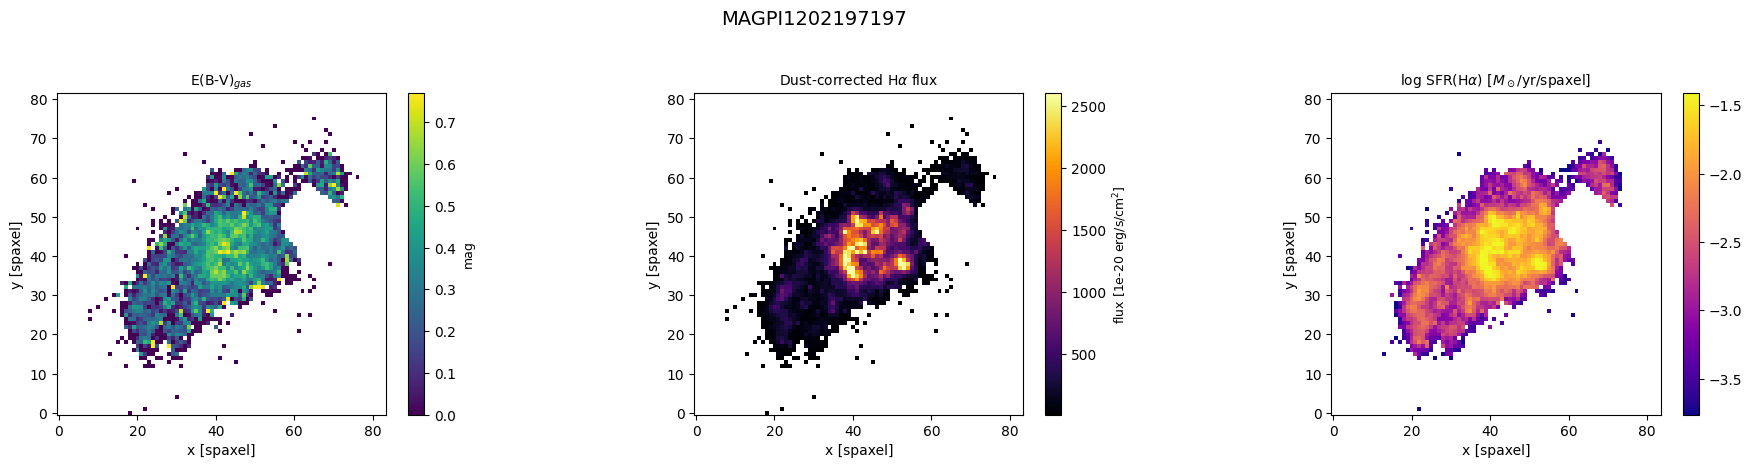

Integrated (within dilated mask) E(B-V)_gas = 0.306 mag
Integrated SFR(Ha) = 7.941 Msun/yr  (log SFR = 0.900)


In [324]:
good_balmer = (Ha_SNR >= SN_BALMER_CUT) & (Hb_SNR >= SN_BALMER_CUT)

EBV_gas = np.full((gal.ny, gal.nx), np.nan)
ratio = Ha_F / Hb_F
EBV_gas_calc = safe_log10(ratio / CASE_B_RATIO) / (0.4 * (k_Hb - k_Ha))
EBV_gas[good_balmer] = EBV_gas_calc[good_balmer]
EBV_gas[EBV_gas < 0] = 0.0

# Dust-corrected Ha flux and luminosity -> SFR
Ha_F_corr = Ha_F * 10 ** (0.4 * k_Ha * EBV_gas)
D_cm = cosmo.luminosity_distance(gal.z_spec).to("cm").value
Ha_lum = Ha_F_corr * 1e-20 * 4 * np.pi * D_cm**2   # erg/s per spaxel

SFR_map = np.full((gal.ny, gal.nx), np.nan)
out_mask = (Ha_SNR >= SN_LINE_CUT) & (Hb_SNR >= SN_LINE_CUT &  (gal.dilated_mask == 0))
SFR_map[out_mask] = SFR_CALIB * Ha_lum[out_mask]
logSFR_map = safe_log10(SFR_map)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
plot_map(gal, EBV_gas, r"E(B-V)$_{gas}$", cmap="viridis",
         vmin=0, cbar_label="mag", ax=axes[0], mask_dilated=True)
plot_map(gal, Ha_F_corr, r"Dust-corrected H$\alpha$ flux", cmap="inferno",
         cbar_label="flux [1e-20 erg/s/cm$^2$]", ax=axes[1], mask_dilated=True)
plot_map(gal, logSFR_map, r"log SFR(H$\alpha$) [$M_\odot$/yr/spaxel]", cmap="plasma",
         ax=axes[2], mask_dilated=True)
fig.suptitle(f"MAGPI{gal.magpiid}", y=1.03, fontsize=14)
fig.tight_layout()
_savefig(fig, SAVE_FIGS, f"MAGPI{gal.magpiid}_EBVgas_SFR_maps.{FIG_FORMAT}")
plt.show()

total_Ha = np.nansum(Ha_F[gal.dilated_mask == 0])
total_Hb = np.nansum(Hb_F[gal.dilated_mask == 0])
total_EBV = max(0.0, np.log10((total_Ha / total_Hb) / CASE_B_RATIO) / (0.4 * (k_Hb - k_Ha)))
total_Ha_corr = total_Ha * 10 ** (0.4 * k_Ha * total_EBV)
total_Ha_lum = total_Ha_corr * 1e-20 * 4 * np.pi * D_cm**2
total_SFR = SFR_CALIB * total_Ha_lum
print(f"Integrated (within dilated mask) E(B-V)_gas = {total_EBV:.3f} mag")
print(f"Integrated SFR(Ha) = {total_SFR:.3f} Msun/yr  (log SFR = {np.log10(total_SFR):.3f})")


## 3. BPT diagnostic diagrams

Classification lines from Kewley et al. (2001,2006), Kauffmann et al. (2003):

- **[NII]/H$\alpha$ vs [OIII]/H$\beta$**
  - Star-forming / Composite Boundary (Kauffmann+03):  
    $\log(OIII/H\beta) = \dfrac{0.61}{\log(NII/H\alpha) - 0.05} + 1.3$
  - Composite / AGN Boundary (Kewley+01):  
    $\log(OIII/H\beta) = \dfrac{0.61}{\log(NII/H\alpha) - 0.47} + 1.19$


- **[SII]/H$\alpha$ vs [OIII]/H$\beta$**
  - Star-forming / AGN Boundary (Kewley+06):  
    $\log(OIII/H\beta) = \dfrac{0.72}{\log(SII/H\alpha) - 0.32} + 1.30$

All ratios require S/N $\geq$ `SN_LINE_CUT` in the lines used.


In [326]:
def bpt_line_nii_ke01(x):
    return 0.61 / (x - 0.47) + 1.19

def bpt_line_nii_ka03(x):
    return 0.61 / (x - 0.05) + 1.3

def bpt_line_sii_ke06(x):
    return 0.72 / (x - 0.32) + 1.30


log_NII_Ha = safe_log10(NII_F / Ha_F)
log_SII_Ha = safe_log10(SII_tot_F / Ha_F)
log_OIII_Hb = safe_log10(OIII_F / Hb_F)

nii_ratio_mask = (Ha_SNR >= SN_LINE_CUT) & (Hb_SNR >= SN_LINE_CUT) & \
                 (OIII_SNR >= SN_LINE_CUT) & (NII_SNR >= SN_LINE_CUT)
sii_ratio_mask = (Ha_SNR >= SN_LINE_CUT) & (Hb_SNR >= SN_LINE_CUT) & \
                 (OIII_SNR >= SN_LINE_CUT) & (SII_SNR >= SN_LINE_CUT)

ka03_div = bpt_line_nii_ka03(log_NII_Ha)
ke01_div = bpt_line_nii_ke01(log_NII_Ha)

sfg = nii_ratio_mask & (log_OIII_Hb < ka03_div) & (log_OIII_Hb < ke01_div)
comp = nii_ratio_mask & (log_OIII_Hb >= ka03_div) & (log_OIII_Hb < ke01_div)
agn = nii_ratio_mask & (log_OIII_Hb >= ke01_div)

ke06_sii_div = bpt_line_sii_ke06(log_SII_Ha)
sfg_sii = sii_ratio_mask & (log_OIII_Hb < ke06_sii_div)
agn_sii = sii_ratio_mask & (log_OIII_Hb >= ke06_sii_div)

# spatial BPT classification map: 0=unclassified,1=SFG,2=Composite,3=AGN
BPT_map = np.zeros((gal.ny, gal.nx), dtype=int)
BPT_map[sfg] = 1
BPT_map[comp] = 2
BPT_map[agn] = 3

print(f"N spaxels: SFG={sfg.sum()}  Composite={comp.sum()}  AGN={agn.sum()}  "
      f"(S/N>={SN_LINE_CUT} in all lines used)")


N spaxels: SFG=960  Composite=122  AGN=0  (S/N>=3 in all lines used)


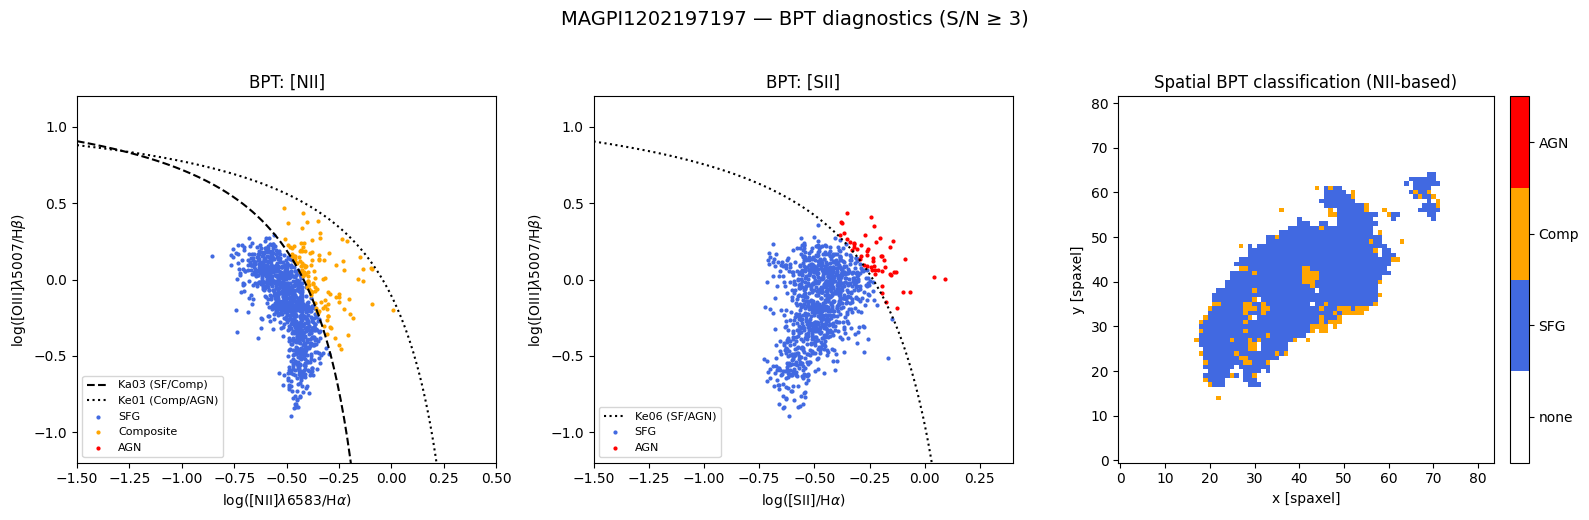

In [327]:
def plot_bpt(save=None, filename=None):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # --- NII diagram ---
    ax = axes[0]
    x1 = np.linspace(-1.5, 0.0, 200)   # Ka03 valid range x<0.05
    x2 = np.linspace(-1.5, 0.4, 200)   # Ke01 valid range x<0.47
    ax.plot(x1, bpt_line_nii_ka03(x1), "k--", lw=1.5, label="Ka03 (SF/Comp)")
    ax.plot(x2, bpt_line_nii_ke01(x2), "k:", lw=1.5, label="Ke01 (Comp/AGN)")
    ax.scatter(log_NII_Ha[sfg], log_OIII_Hb[sfg], s=4, c="royalblue", label="SFG")
    ax.scatter(log_NII_Ha[comp], log_OIII_Hb[comp], s=4, c="orange", label="Composite")
    ax.scatter(log_NII_Ha[agn], log_OIII_Hb[agn], s=4, c="red", label="AGN")
    ax.set_xlabel(r"log([NII]$\lambda6583$/H$\alpha$)")
    ax.set_ylabel(r"log([OIII]$\lambda5007$/H$\beta$)")
    ax.set_xlim(-1.5, 0.5); ax.set_ylim(-1.2, 1.2)
    ax.legend(fontsize=8, loc="lower left")
    ax.set_title("BPT: [NII]")

    # --- SII diagram ---
    ax = axes[1]
    x2 = np.linspace(-1.5, 0.3, 200)
    ax.plot(x2, bpt_line_sii_ke06(x2), "k:", lw=1.5, label="Ke06 (SF/AGN)")
    ax.scatter(log_SII_Ha[sfg_sii], log_OIII_Hb[sfg_sii], s=4, c="royalblue", label="SFG")
    ax.scatter(log_SII_Ha[agn_sii], log_OIII_Hb[agn_sii], s=4, c="red", label="AGN")
    ax.set_xlabel(r"log([SII]/H$\alpha$)")
    ax.set_ylabel(r"log([OIII]$\lambda5007$/H$\beta$)")
    ax.set_xlim(-1.5, 0.4); ax.set_ylim(-1.2, 1.2)
    ax.legend(fontsize=8, loc="lower left")
    ax.set_title("BPT: [SII]")

    # --- spatial map ---
    ax = axes[2]
    cmap = mcolors.ListedColormap(["white", "royalblue", "orange", "red"])
    im = ax.imshow(BPT_map, cmap=cmap, vmin=-0.5, vmax=3.5)
    cb = fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], fraction=0.046, pad=0.04)
    cb.ax.set_yticklabels(["none", "SFG", "Comp", "AGN"])
    ax.set_title("Spatial BPT classification (NII-based)")
    ax.set_xlabel("x [spaxel]"); ax.set_ylabel("y [spaxel]")

    fig.suptitle(f"MAGPI{gal.magpiid} — BPT diagnostics (S/N \u2265 {SN_LINE_CUT})", y=1.03, fontsize=14)
    fig.tight_layout()
    if filename is None:
        filename = f"MAGPI{gal.magpiid}_BPT.{FIG_FORMAT}"
    _savefig(fig, save, filename)
    plt.show()


plot_bpt()


## 4. Gas-phase metallicity: N2S2 calibration (Dopita et al. 2016)

$y = \log_{10}([NII]/[SII]) + 0.264\,\log_{10}([NII]/H\alpha)$

$12+\log(O/H) = 8.77 + y + 0.45\,(y+0.3)^5$

Requires S/N $\geq$ `SN_LINE_CUT` in H$\alpha$, [NII], and [SII]. This diagnostic was chosen as the example because dust corrections are not required (since the lines ratios used are close in wavelength). Metallicity calibrations can have large offsets, so consider which one you adopt with care. 


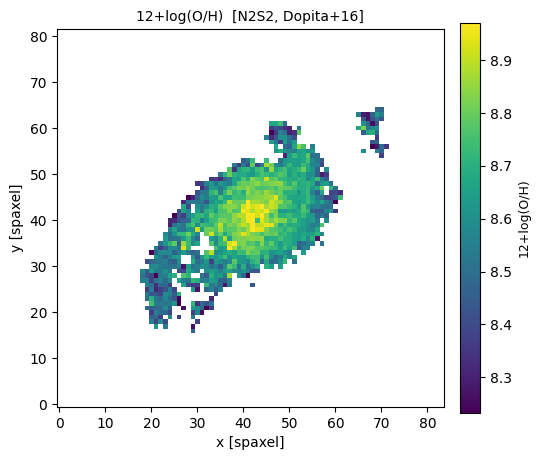

Median 12+log(O/H) = 8.644  (958 good spaxels)


In [329]:
def metallicity_n2s2_d16(log_n2s2, log_n2ha):
    y = log_n2s2 + 0.264 * log_n2ha
    return 8.77 + y + 0.45 * (y + 0.3) ** 5


good_N2S2 = (NII_SNR >= SN_LINE_CUT) & (SII_SNR >= SN_LINE_CUT) & (Ha_SNR >= SN_LINE_CUT)

log_N2S2 = safe_log10(NII_F / SII_tot_F)
log_N2Ha = safe_log10(NII_F / Ha_F)

logOH_N2S2 = np.full((gal.ny, gal.nx), np.nan)
vals = metallicity_n2s2_d16(log_N2S2, log_N2Ha)
logOH_N2S2[good_N2S2] = vals[good_N2S2]

plot_map(gal, logOH_N2S2, "12+log(O/H)  [N2S2, Dopita+16]", cmap="viridis",
         cbar_label="12+log(O/H)", save=False)

if np.any(np.isfinite(logOH_N2S2)):
    print(f"Median 12+log(O/H) = {np.nanmedian(logOH_N2S2):.3f}  "
          f"({np.isfinite(logOH_N2S2).sum()} good spaxels)")
else:
    print("No spaxels pass the S/N cuts for the N2S2 metallicity in this galaxy.")


## 5. Quality-cut D4000 and gas velocity maps

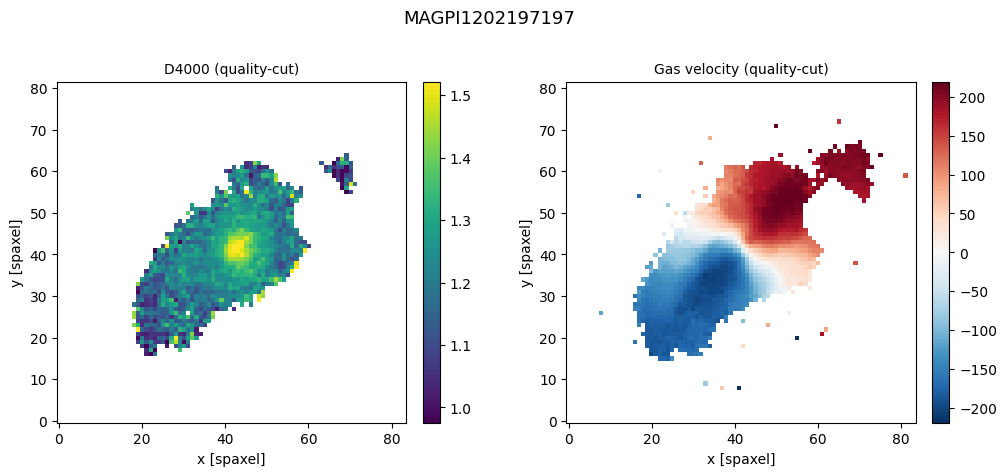

In [331]:
D4000_obs = gal["D4000_OBS"]
D4000_obs_err = gal["D4000_OBS_ERR"]

good_D4000 = (snr(D4000_obs, D4000_obs_err) >= D4000_SN_CUT) & (D4000_obs < D4000_MAX)
out_mask_lines = (Ha_SNR >= SN_LINE_CUT) & (Hb_SNR >= SN_LINE_CUT) & (gal.dilated_mask == 0)  # same as out_mask above

D4000_clean = np.full((gal.ny, gal.nx), np.nan)
D4000_clean[good_D4000 & out_mask_lines] = D4000_obs[good_D4000 & out_mask_lines]

V_GAS = gal["V_GAS"]
VERR_GAS = gal["VERR_GAS"]
good_vel = (VERR_GAS <= VEL_ERR_CUT) & (gal.dilated_mask == 0) & \
           ((OII_SNR >= SN_LINE_CUT) | (Hb_SNR >= SN_LINE_CUT) |
            (OIII_SNR >= SN_LINE_CUT) | (Ha_SNR >= SN_LINE_CUT))
V_GAS_clean = np.full((gal.ny, gal.nx), np.nan)
V_GAS_clean[good_vel] = V_GAS[good_vel]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5))
plot_map(gal, D4000_clean, "D4000 (quality-cut)", cmap="viridis", ax=axes[0])
plot_map(gal, V_GAS_clean, "Gas velocity (quality-cut)", symmetric=True, ax=axes[1])
fig.suptitle(f"MAGPI{gal.magpiid}", y=1.03, fontsize=13)
fig.tight_layout()
_savefig(fig, SAVE_FIGS, f"MAGPI{gal.magpiid}_D4000_Vgas_clean.{FIG_FORMAT}")
plt.show()


## 6. Save everything at once

Regenerate every figure above with saving switched on.

In [333]:
def make_all_plots(save=True):
    global SAVE_FIGS
    prev = SAVE_FIGS
    SAVE_FIGS = save
    try:
        plot_all_extensions(gal, save=save)
        plot_bpt(save=save)
        plot_map(gal, logOH_N2S2, "12+log(O/H)  [N2S2, Dopita+16]", cmap="viridis",
                 cbar_label="12+log(O/H)", save=save)
    finally:
        SAVE_FIGS = prev

# make_all_plots(save=True)   # uncomment to write all figures to OUTPUT_DIR
